# Apply bias adjustment to climate projection data

Every climate model shows a deviation from climatology, called bias. The procedure to correct or limit this error is called Bias Adjustment (BA).

Period 1950-1999 is used for training the model on ERA5, period 2000-2014 is used to test the model on the historical experiment of NEX-GDDP-CMIP6, then the adjustment is applied to scenario experiments for period 2024-2100.
A q-q plot is made to test the performance of the BA against the test set.

For the midterm discussion, a variation of Quantile Mapping (QM) approach is used, the Quantile Delta Mapping (QDM) algorithm, and it is applied to variables derived from `tas` and `pr`. The number of quantiles selected for the adjustment is 100, to treat them as percent point.

In [1]:
import matplotlib.pyplot as plt
import numpy
import xarray
import xclim.sdba

import thesis

xarray.set_options(keep_attrs=True)

In [2]:
location = "torino"  # Select the spatial center of the analysis, cf. thesis.coords keys.

dir_data = thesis.dir_data / location / "preprocessed"

dir_out = dir_data.parent / "adjusted"
dir_out.mkdir(parents=True, exist_ok=True)

In [3]:
chunks = {"latitude": 1, "longitude": 1, "time": 1000}
ds_reference = xarray.open_dataset(dir_data / "reference.nc", chunks=chunks)

ds_historical = xarray.open_mfdataset(
    dir_data.glob("historical*.nc"),
    chunks=chunks,
    combine_attrs="drop_conflicts"
)

concat_dim = "scenario"
ds_scenario = xarray.open_mfdataset(
    dir_data.glob("ssp*.nc"),
    chunks=chunks,
    concat_dim=concat_dim,
    combine="nested",
    combine_attrs="drop_conflicts"
)
ds_scenario = ds_scenario.assign_coords({concat_dim: list(thesis.scenario)})

# Collect all datasets in an iterator for programmatic access.
dict_dataset = {"reference": ds_reference, "historical": ds_historical}
dict_dataset.update({s: ds_scenario.loc[{concat_dim: s}].reset_coords(drop=True) for s in thesis.scenario})

# Collect all datasets in a single dataset for convenience in plotting.
data_dim = "experiment"
ds_data = xarray.concat(
    dict_dataset.values(),  # From Python 3.7 dict preserves order.
    data_dim,
    combine_attrs="drop_conflicts"
)
ds_data = ds_data.assign_coords({data_dim: list(dict_dataset.keys())})
ds_data = ds_data.chunk(chunks)

_groupby = ds_reference.sel(time=thesis.baseline_period).groupby("time.dayofyear")
ds_climatology = _groupby.mean(dim="time").assign_coords({"quantity": "mean"})
ds_climatology = xarray.concat(
    [ds_climatology, _groupby.std(dim="time").assign_coords({"quantity": "std"})],
    dim="quantity"
)

In [4]:
def _coordinates_facet(xobject: xarray.Dataset | xarray.DataArray):
    # Assume coordinates are in ascending order, hence facet plot is created
    # by assigning lowest index to top left axes. Align axes position
    # with spatial position for a more intuitive reading of the figure.
    # Cf. https://stackoverflow.com/a/72970086.
    return xobject.isel(latitude=slice(None, None, -1))

def plot_coordinates_facet(da, **kwargs):
    da = _coordinates_facet(da)
    row = kwargs.pop("row", "latitude")
    col = kwargs.pop("col", "longitude")
    _plot = da.plot(col=col, row=row, **kwargs)
    return _plot

def plot_yearly_mean_time_series_facet(da, **kwargs):
    da = da.resample(time="YS").mean()
    _plot = plot_coordinates_facet(da, hue=data_dim, **kwargs)
    for ax in _plot.axs.ravel():
        ax.grid(which="both")
        # Make more readable the x axis labels, cf. https://stackoverflow.com/a/49714879,
        # actually performs better than xarray.plot.FacetGrid.set_ticks.
        for i, label in enumerate(ax.xaxis.get_ticklabels()):
            if i % 2 != 0:
                label.set_visible(False)
    return _plot

def plot_scatter_facet(ds, x, y, **kwargs):
    ds = _coordinates_facet(ds)
    row = kwargs.pop("row", "latitude")
    col = kwargs.pop("col", "longitude")
    _plot = ds.plot.scatter(x=x, y=y, col=col, row=row, **kwargs)
    for ax in _plot.axs.ravel():
        ax.grid(which="both")
    return _plot

## BA of daily temperature

First plot the time series of the anomaly with respect to climatology.

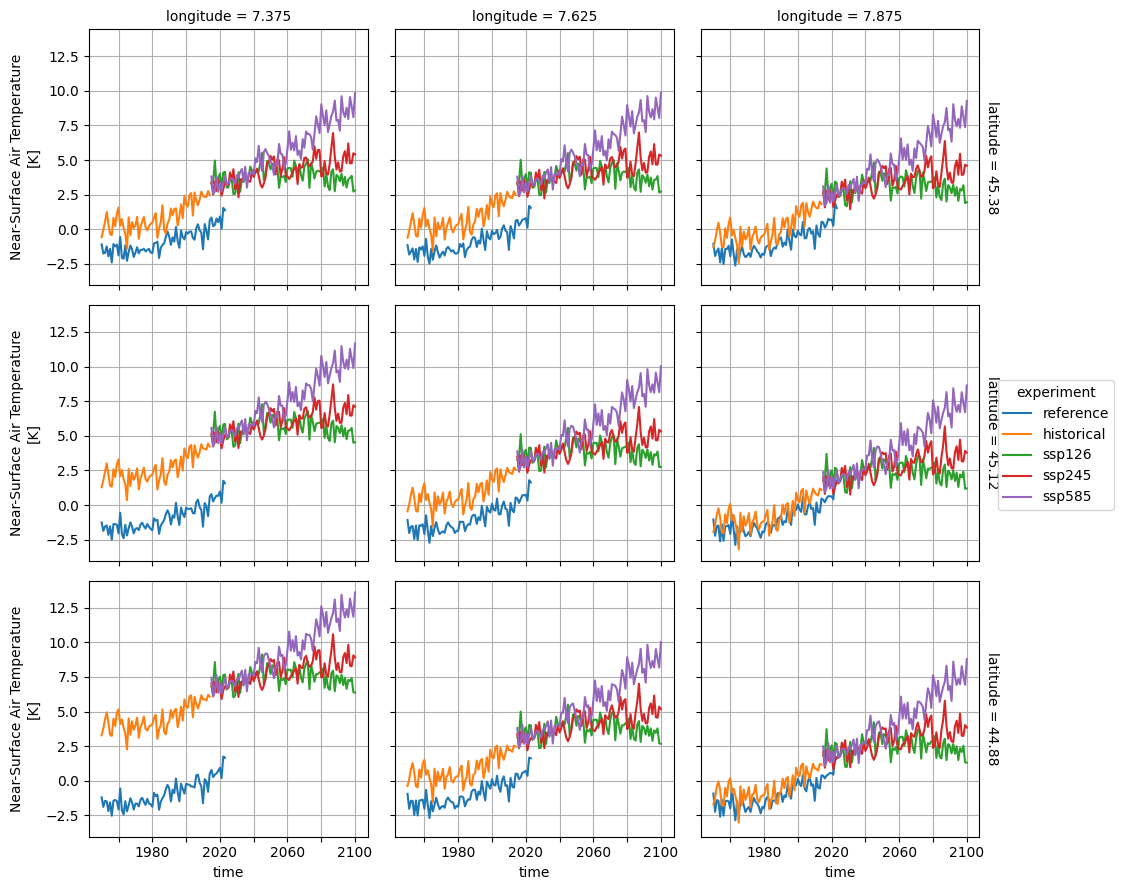

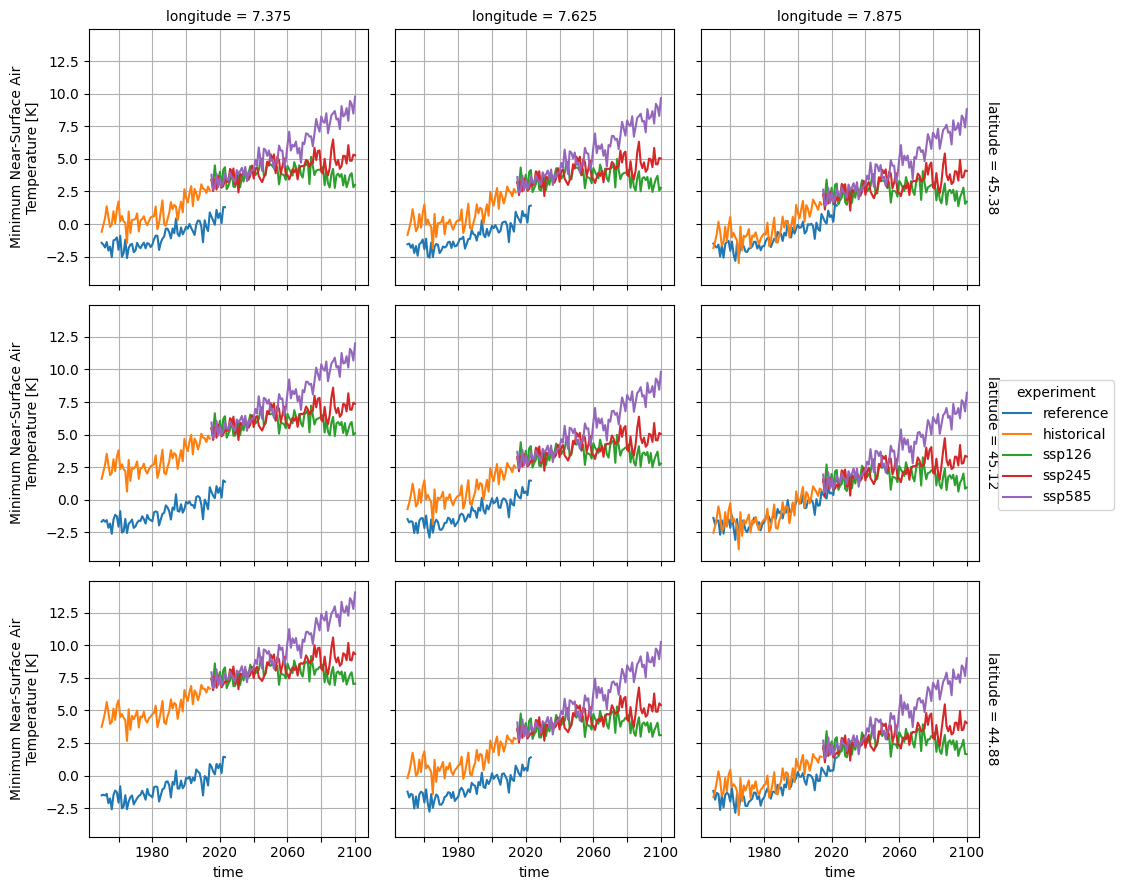

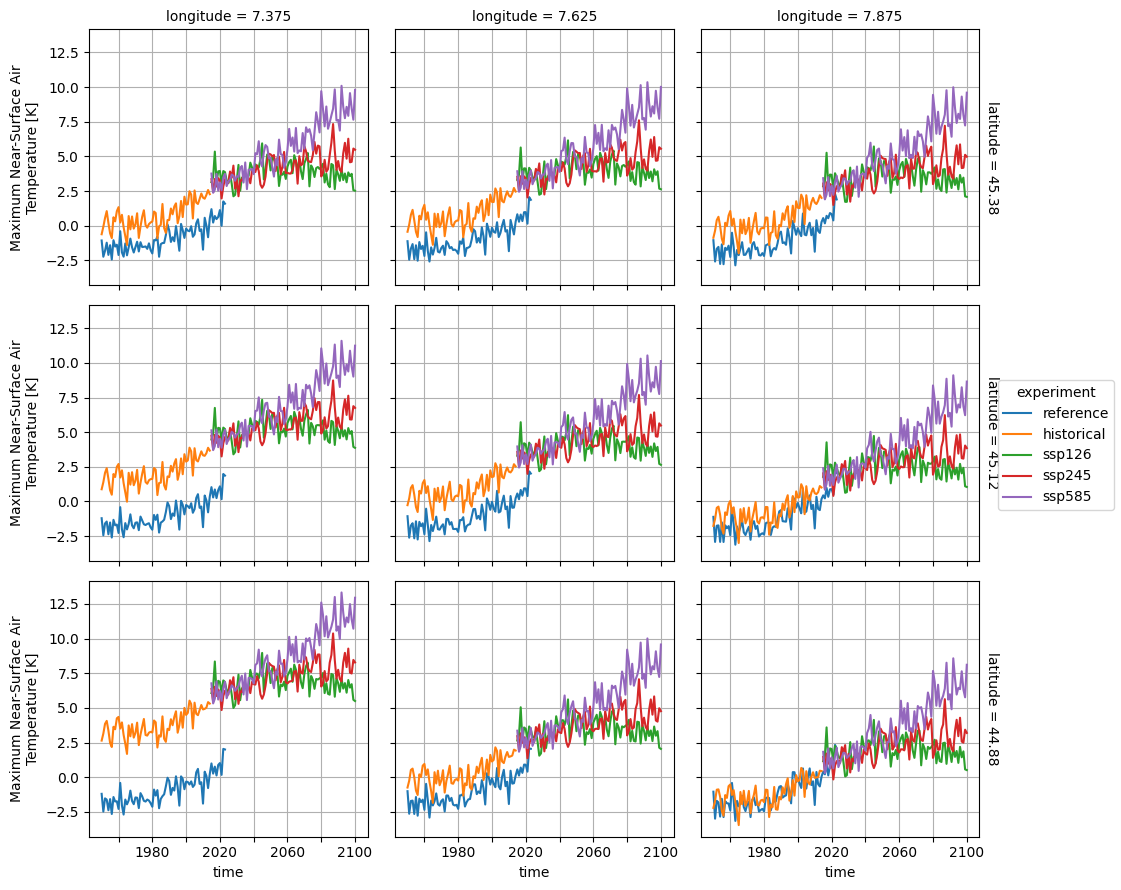

In [5]:
variables = ["tas", "tasmin", "tasmax"]
for v in variables:
    plot_yearly_mean_time_series_facet(ds_data[v].groupby("time.dayofyear") - ds_climatology[v].sel(quantity="mean"))

Then apply QDM, it is additive for temperature.

In [6]:
_ds = ds_data.chunk({"time": -1})  # The implementation of QDM does not work when time is chunked.
ba = {}
_da = {}
for v in variables:
    ba[v] = xclim.sdba.QuantileDeltaMapping.train(
        _ds[v].sel({data_dim: "reference", "time": thesis.training_period}, drop=True),
        _ds[v].sel({data_dim: "historical", "time": thesis.training_period}, drop=True),
        nquantiles=20,
        group="time",
        kind='+'
    )
    _da[v] = ba[v].adjust(_ds[v], interp="linear")
    _da[v].name = v

# Post processing.
ds_adjusted = xarray.Dataset(data_vars=_da, attrs=ds_data.attrs)
ds_adjusted = ds_adjusted.drop_sel({"experiment": "reference"})  # Reference is correct by definition.

Plot the resulting anomaly.

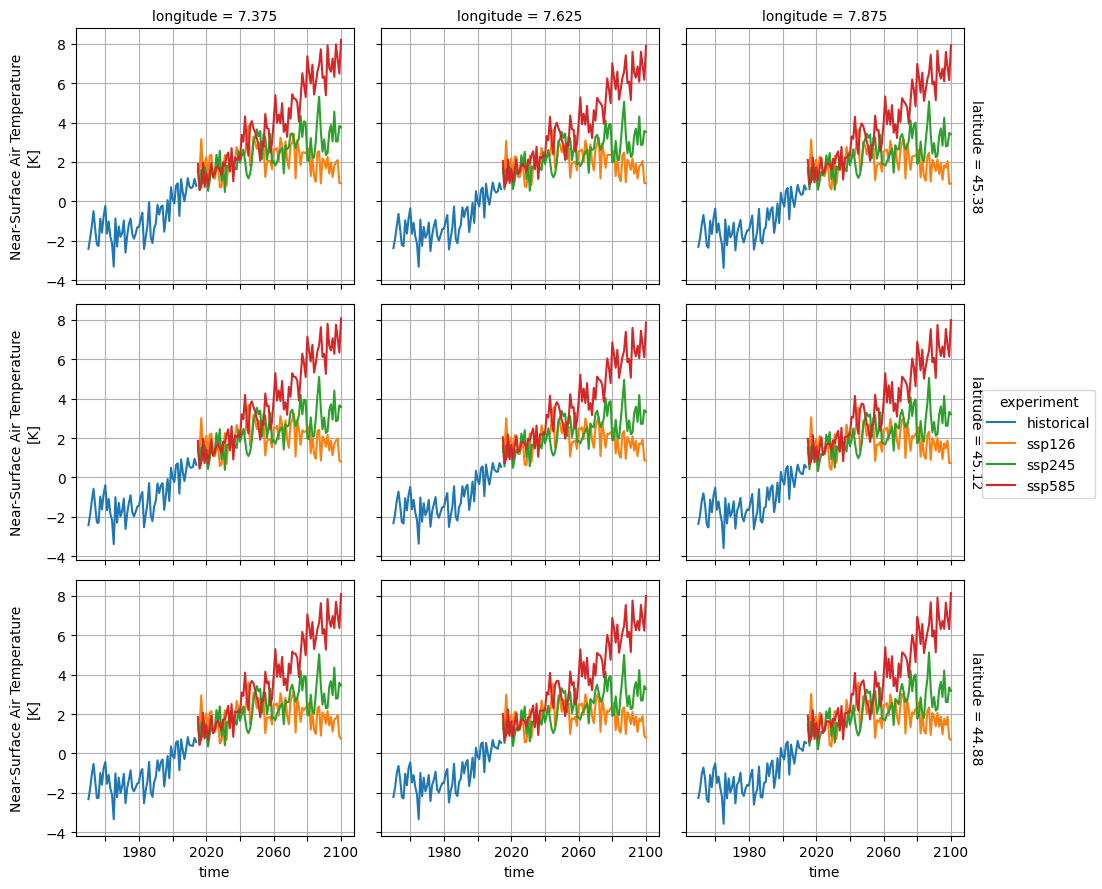

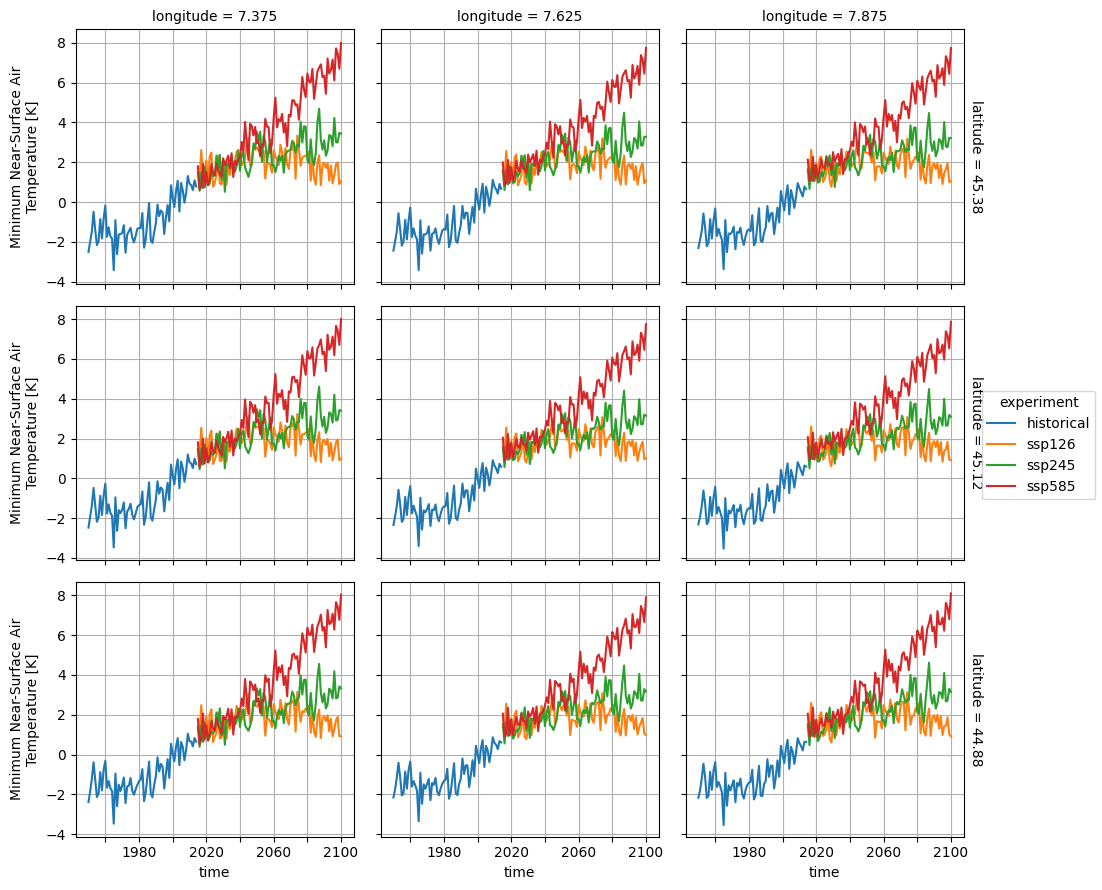

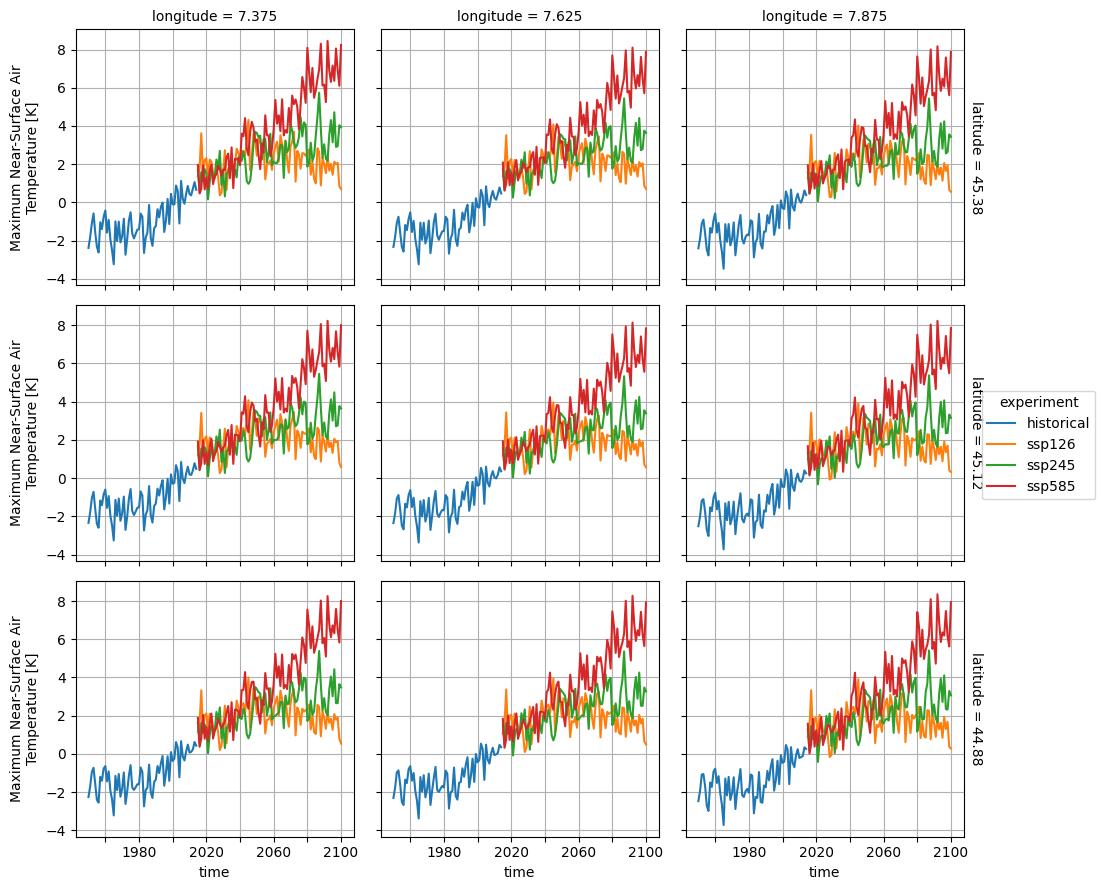

In [7]:
for v in variables:
    plot_yearly_mean_time_series_facet(ds_adjusted[v].groupby("time.dayofyear") - ds_climatology[v].sel(quantity="mean"))

Compare visually the results of BA.

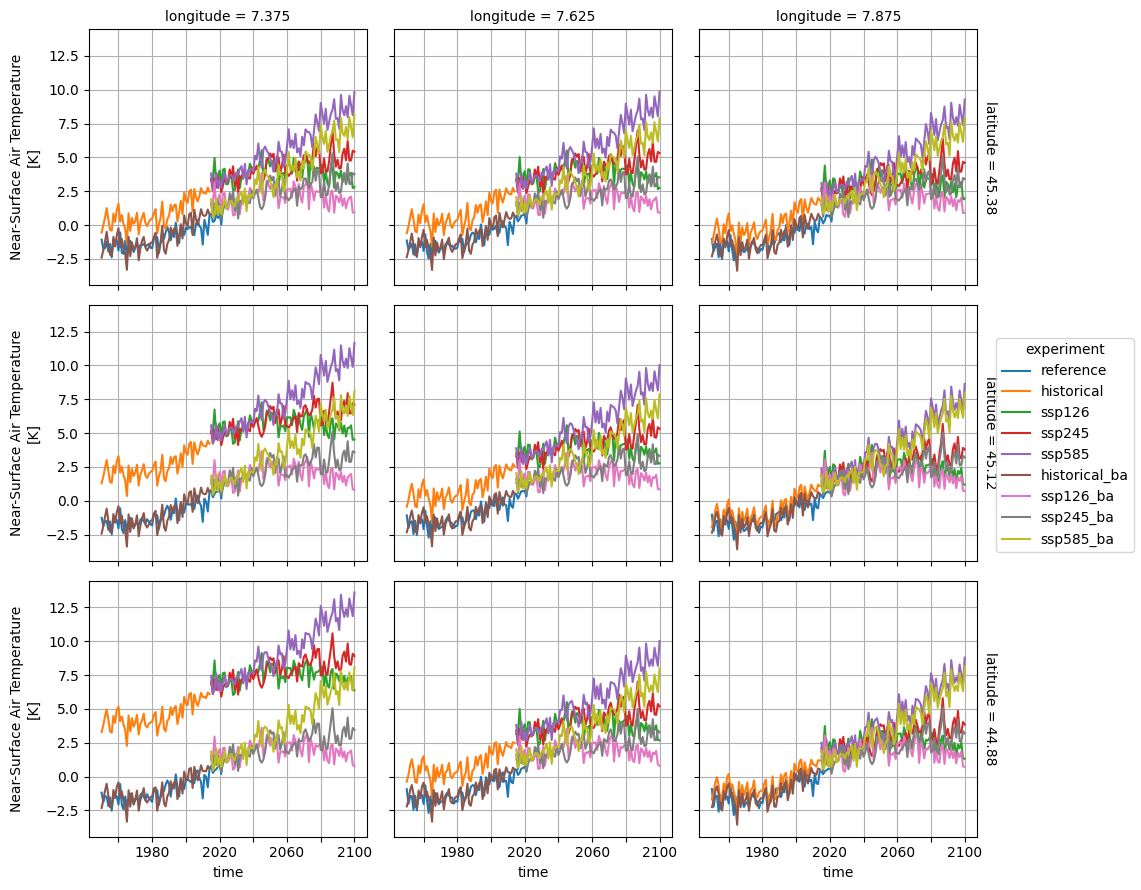

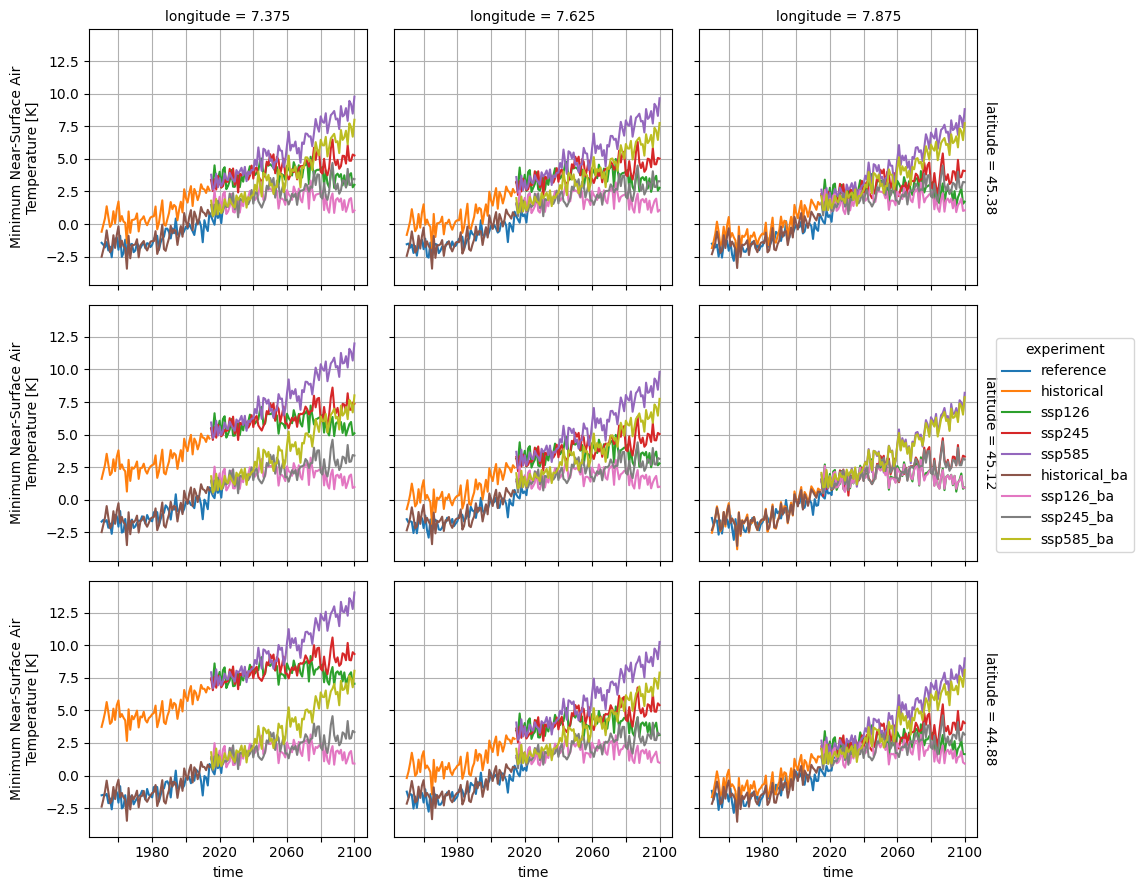

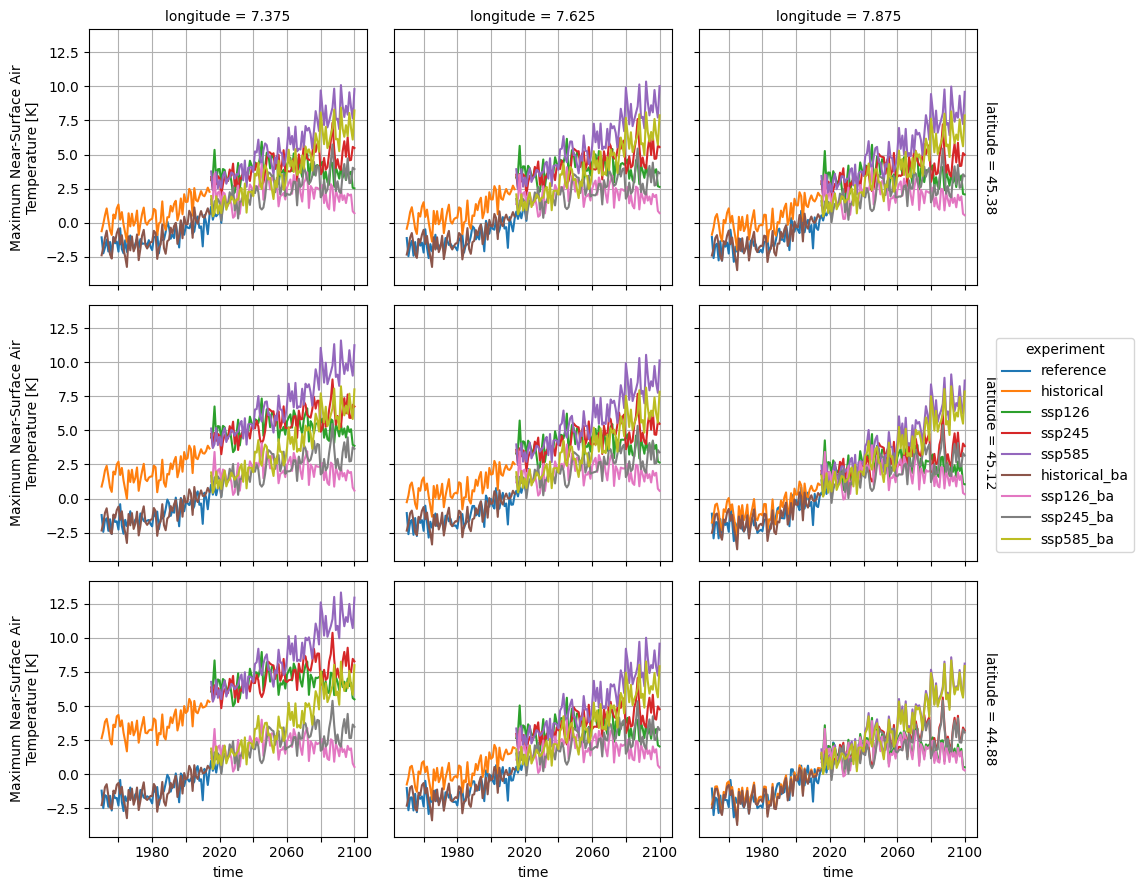

In [8]:
_ds = xarray.concat(
    (ds_data[variables], ds_adjusted[variables].assign_coords({data_dim: ds_adjusted[data_dim].str + "_ba"})),
    data_dim,
    combine_attrs="drop_conflicts"
)
for v in variables:
    plot_yearly_mean_time_series_facet(_ds[v].groupby("time.dayofyear") - ds_climatology[v].sel(quantity="mean"))

## Test BA

Use a period of the historical experiment to assert statistically the quality of the BA.

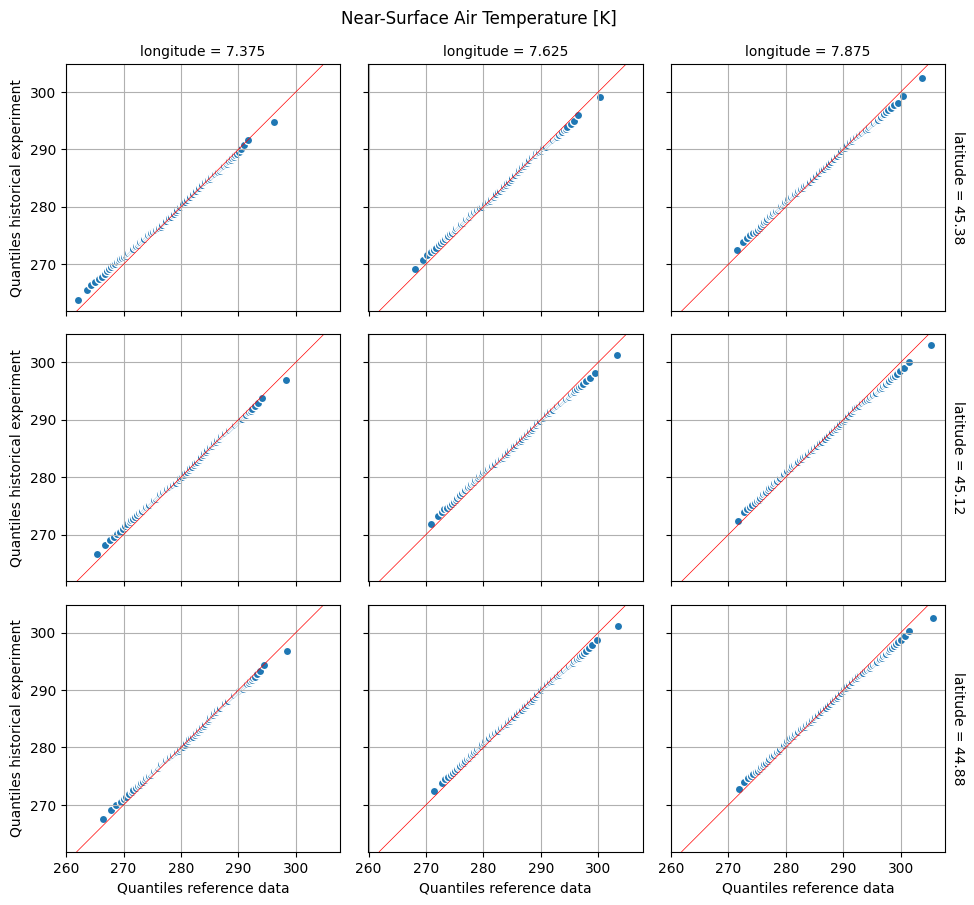

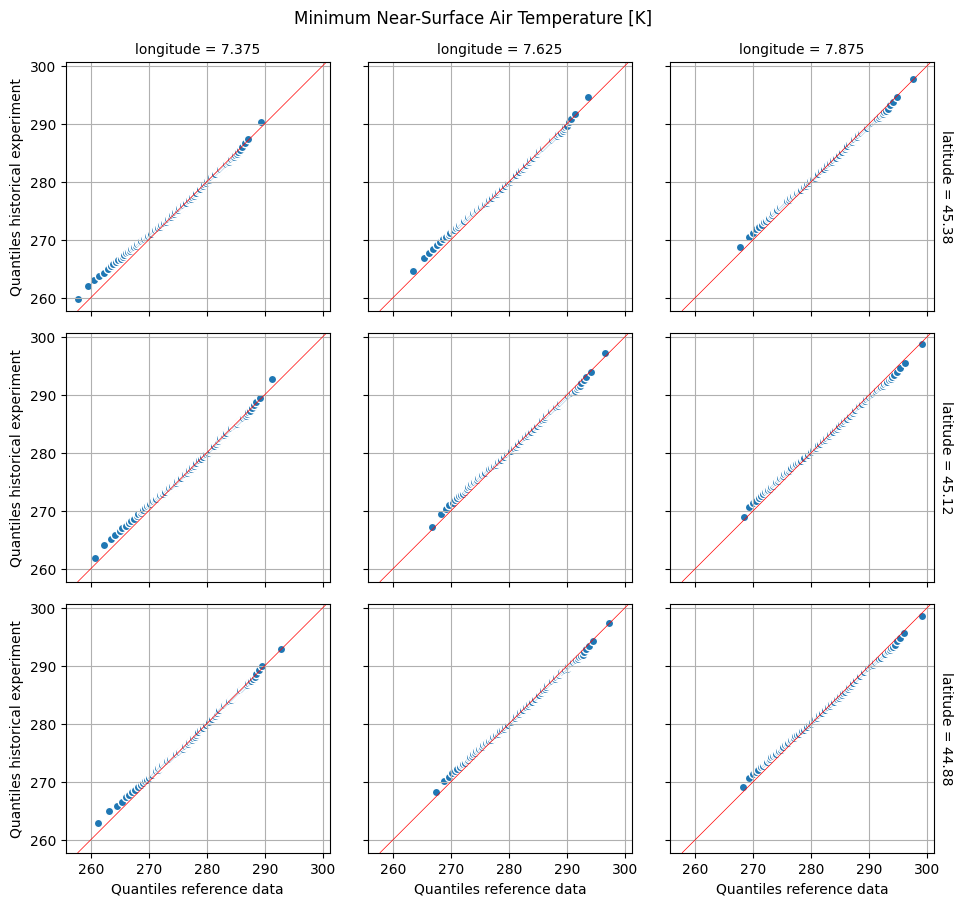

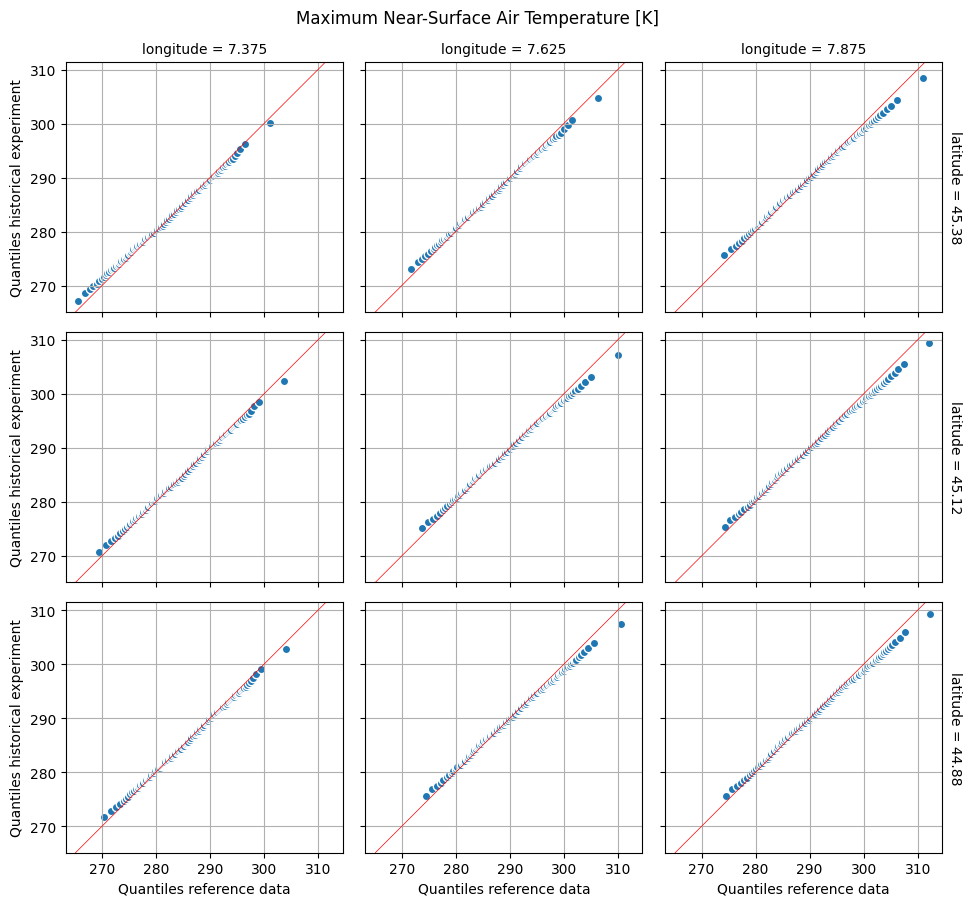

In [9]:
quantiles = numpy.arange(1, 101, 1)
quantiles = quantiles / len(quantiles)

# The implementation of quantile does not work when time is chunked.
_reference = ds_data.sel({data_dim: "reference", "time": thesis.test_period}).chunk({"time": -1})
_historical = ds_adjusted.sel({data_dim: "historical", "time": thesis.test_period}).chunk({"time": -1})
_reference = _reference.quantile(quantiles, dim="time")
_historical = _historical.quantile(quantiles, dim="time")
ds_test = _reference.assign({f"{k}_historical": v for k, v in _historical.data_vars.items()})

for v in variables:
    _plot = plot_scatter_facet(ds_test, x=v, y=f"{v}_historical")
    _plot.fig.suptitle(f"{ds_test[v].attrs['long_name']} [{ds_test[v].attrs['units']}]", y=1, verticalalignment="bottom")
    _plot.set_axis_labels("Quantiles reference data", "Quantiles historical experiment")
    for ax in _plot.axs.ravel():
        ax.axline((0,0), slope=1, color="red", linewidth=0.5)
        ax.set_aspect("equal", adjustable="box")

Store the adjusted data in a file for future use.

In [10]:
for m in thesis.models:
    for e in ds_adjusted[data_dim].values:
        path = dir_out / f"{e}_{m}.nc"
        ds_adjusted.sel({data_dim: e}, drop=True).to_netcdf(path)